In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from metrics import metrics
from model import generics
from input import input
pd.set_option('display.max_rows', 2000)

%load_ext autoreload
%autoreload 2

In [2]:
experiment_id = 'hourwindspeed'

In [3]:
df_mean_metrics, df_all_metrics, df_prevs = metrics.open_fold_result(experiment_id)

/home/domingosjr/experiments/src/metrics/metrics.py:347: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_metric = pd.DataFrame(all_metrics).fillna(-1).infer_objects(copy=False)
/home/domingosjr/experiments/src/metrics/metrics.py:347: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_metric = pd.DataFrame(all_metrics).fillna(-1).infer_objects(copy=False)
/home/domingosjr/experiments/src/metrics/metrics.py:347: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_obje

In [4]:
df_mean_metrics.reset_index()['ts'].unique()

array(['windspeedcampinagrandehour', 'windspeedcaruaruhour',
       'windspeedcastelodopiauihour', 'windspeedmaceiohour',
       'windspeedsalvadorhour'], dtype=object)

In [5]:
df_mean_metrics.reset_index()['model'].unique()

array(['24arima', '24combmean', '24elm', '24elmbagg100.50.5',
       '24elmbagg100.50.8', '24elmbagg100.80.5', '24elmbagg100.80.8',
       '24elmbagg300.50.5', '24elmbagg300.50.8', '24elmbagg300.80.5',
       '24elmbagg300.80.8', '24elmbagg500.50.5', '24elmbagg500.50.8',
       '24elmbagg500.80.5', '24elmbagg500.80.8', '24kan', '24ma', '24mlp',
       '24mlpbagg100.50.5', '24mlpbagg100.50.8', '24mlpbagg100.80.5',
       '24mlpbagg100.80.8', '24mlpbagg300.50.5', '24mlpbagg300.50.8',
       '24mlpbagg300.80.5', '24mlpbagg300.80.8', '24mlpbagg500.50.5',
       '24mlpbagg500.50.8', '24mlpbagg500.80.5', '24mlpbagg500.80.8',
       '24nhits', '24rf100.50.5', '24rf100.50.8', '24rf100.80.5',
       '24rf100.80.8', '24rf300.50.5', '24rf300.50.8', '24rf300.80.5',
       '24rf300.80.8', '24rf500.50.5', '24rf500.50.8', '24rf500.80.5',
       '24rf500.80.8', '24svr', '24tcn', '48arima', '48combmean', '48elm',
       '48elmbagg100.50.5', '48elmbagg100.50.8', '48elmbagg100.80.5',
       '48elmbagg100

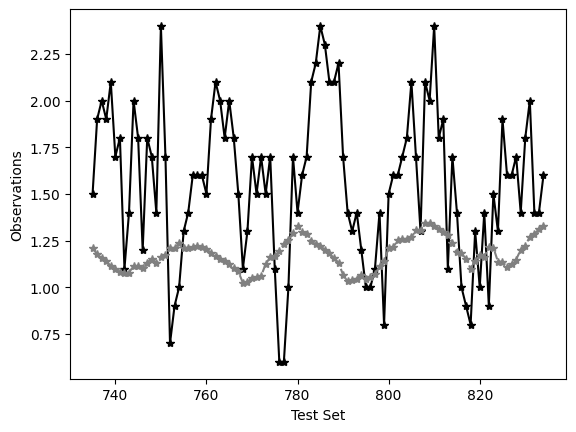

In [13]:
ts = 'windspeedsalvadorhour'
models = ['72mlpbagg500.80.8']
to_plot = ['real'] + models
df_plot = df_prevs[((df_prevs['ts'] == ts) & (df_prevs['model'].isin(to_plot)))].copy()
df_plot = df_plot.pivot(index='id', values='prev', columns='model')

ax = df_plot[to_plot].iloc[-100:].plot(
    style=['*-', '*--'], 
    color=['black', 'gray'],
    legend=False
)

# Adicionando as legendas dos eixos
ax.set_ylabel('Observations')
ax.set_xlabel('Test Set')
plt.savefig(f'{ts}72.pdf', format='pdf', bbox_inches='tight')
plt.show()


In [32]:
df_plot['ape'] = abs(df_plot['1svr'] - df_plot['real'] ) /  df_plot['real'] 

In [9]:
df_plot

model,24elmbagg1000.80.8,real
id,,
0,3.788327,3.814035
1,3.786728,3.812281
2,3.785128,3.810526
3,3.783528,3.808772
4,3.781929,3.807018
5,3.780329,3.805263
6,3.778729,3.803509
7,3.777128,3.801754
8,3.775528,3.800000
